In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

1: Inspect the Dataset
The dataset contains 240 software support tickets and 6 columns. I checked the data types, missing values, duplicate IDs, and basic statistics to understand the data before building the model. There were no missing values, and each ticket had a unique ID.

In [4]:
features = ["complexity_score", "team_experience_years"]

X = df[features]
y = df["resolution_hours"]

print("Input features:")
display(X.head())

print("Target:")
display(y.head())

Input features:


,complexity_score,team_experience_years
0,6,5.6
1,9,11.5
2,6,3.3
3,5,9.6
4,3,6.4


Target:


0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64

2: Select Features and Target
I selected resolution_hours as the target variable (y) because it is what I want to predict. I used complexity_score and team_experience_years as input features (X). I excluded ticket_id because it is only an identifier and left out lines_changed and reopened because they might not be known when a ticket first arrives.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 192
Testing rows: 48


In [ ]:
3: Split the Dataset
I split the dataset into 80% training data and 20% testing data. The training data is used to teach the model, while the testing data is used to check how well it predicts results for data it has not trained on. I used random_state=42 to make the split reproducible.

In [6]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return predictions, {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


baseline = DummyRegressor(strategy="mean")

baseline_predictions, baseline_metrics = evaluate_model(
    baseline, X_train, y_train, X_test, y_test
)

print("Baseline results:")
print(baseline_metrics)

Baseline results:
{'MAE': 9.113951822916667, 'RMSE': np.float64(10.597684800766308), 'R2': -0.021016765260001957}


4: Create a Baseline Model
I used a DummyRegressor as the baseline model. It predicts the average resolution time from the training data for every ticket. This gives me a simple result to compare with the other models.

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)

print("MAE:", mean_absolute_error(y_test, linear_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, linear_predictions)))
print("R2:", r2_score(y_test, linear_predictions))

MAE: 2.9060129859502593
RMSE: 3.5722743548797085
R2: 0.883988648014197


5: Train Linear and Polynomial Regression Models
I trained a Linear Regression model and Polynomial Regression models with degrees 2 and 3. Linear Regression models a straight-line relationship, while Polynomial Regression can capture more complex relationships. I compared their results to see which model performed better on the test data.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

results = []

# Save the linear regression results
results.append({
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, linear_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, linear_predictions)),
    "R2": r2_score(y_test, linear_predictions)
})

# Train polynomial regression models
for degree in [2, 3]:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": f"Polynomial Degree {degree}",
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

import pandas as pd

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,2.906,3.572,0.884
1,Polynomial Degree 2,3.020,3.741,0.873
2,Polynomial Degree 3,3.140,3.949,0.858


In [ ]:
6: Train Ridge and Lasso Models
I trained Ridge and Lasso Regression models with feature scaling and tested different alpha values using cross-validation. These models use regularization to reduce the effect of overly large coefficients and help control overfitting. I used the best alpha values selected during cross-validation.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Store our models, predictions, and results
models = {}
predictions = {}
results = []

# 1. Baseline: always predict the average training resolution time
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
models["Mean Baseline"] = baseline
predictions["Mean Baseline"] = baseline.predict(X_test)

# 2. Linear Regression with scaling
linear = make_pipeline(StandardScaler(), LinearRegression())
linear.fit(X_train, y_train)
models["Linear Regression"] = linear
predictions["Linear Regression"] = linear.predict(X_test)

# 3. Polynomial Regression: degrees 2 and 3
for degree in [2, 3]:
    poly = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    # Evaluate using five-fold cross-validation on training data
    cv_scores = cross_val_score(
        poly,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print(
        f"Degree {degree} - Average CV MAE:",
        round(-cv_scores.mean(), 3)
    )

    # Train on all training data, then evaluate on test data
    poly.fit(X_train, y_train)
    name = f"Polynomial Degree {degree}"
    models[name] = poly
    predictions[name] = poly.predict(X_test)

# 4. Ridge and Lasso: use cross-validation to select alpha
alpha_values = [0.01, 0.1, 1, 10, 100]

for name, estimator in [
    ("Ridge", Ridge()),
    ("Lasso", Lasso(max_iter=10000))
]:
    pipeline = make_pipeline(StandardScaler(), estimator)

    search = GridSearchCV(
        pipeline,
        param_grid={"ridge__alpha": alpha_values}
        if name == "Ridge"
        else {"lasso__alpha": alpha_values},
        scoring="neg_mean_absolute_error",
        cv=5
    )

    search.fit(X_train, y_train)

    models[name] = search.best_estimator_
    predictions[name] = search.predict(X_test)

    print(
        f"{name} best alpha:",
        search.best_params_
    )

# 5. Compare all models on the same test set
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(3))

Degree 2 - Average CV MAE: 3.175
Degree 3 - Average CV MAE: 3.132
Ridge best alpha: {'ridge__alpha': 1}
Lasso best alpha: {'lasso__alpha': 0.01}


,Model,MAE,RMSE,R2
4,Ridge,2.905,3.571,0.884
1,Linear Regression,2.906,3.572,0.884
5,Lasso,2.907,3.572,0.884
2,Polynomial Degree 2,3.020,3.741,0.873
3,Polynomial Degree 3,3.140,3.949,0.858
0,Mean Baseline,9.114,10.598,-0.021


7: Evaluate and Compare the Models
I compared the models using MAE, RMSE, and R². MAE shows the average prediction error in hours, RMSE gives more weight to larger errors, and R² shows how well the model explains variation in resolution time. I used these metrics to compare each model's performance.

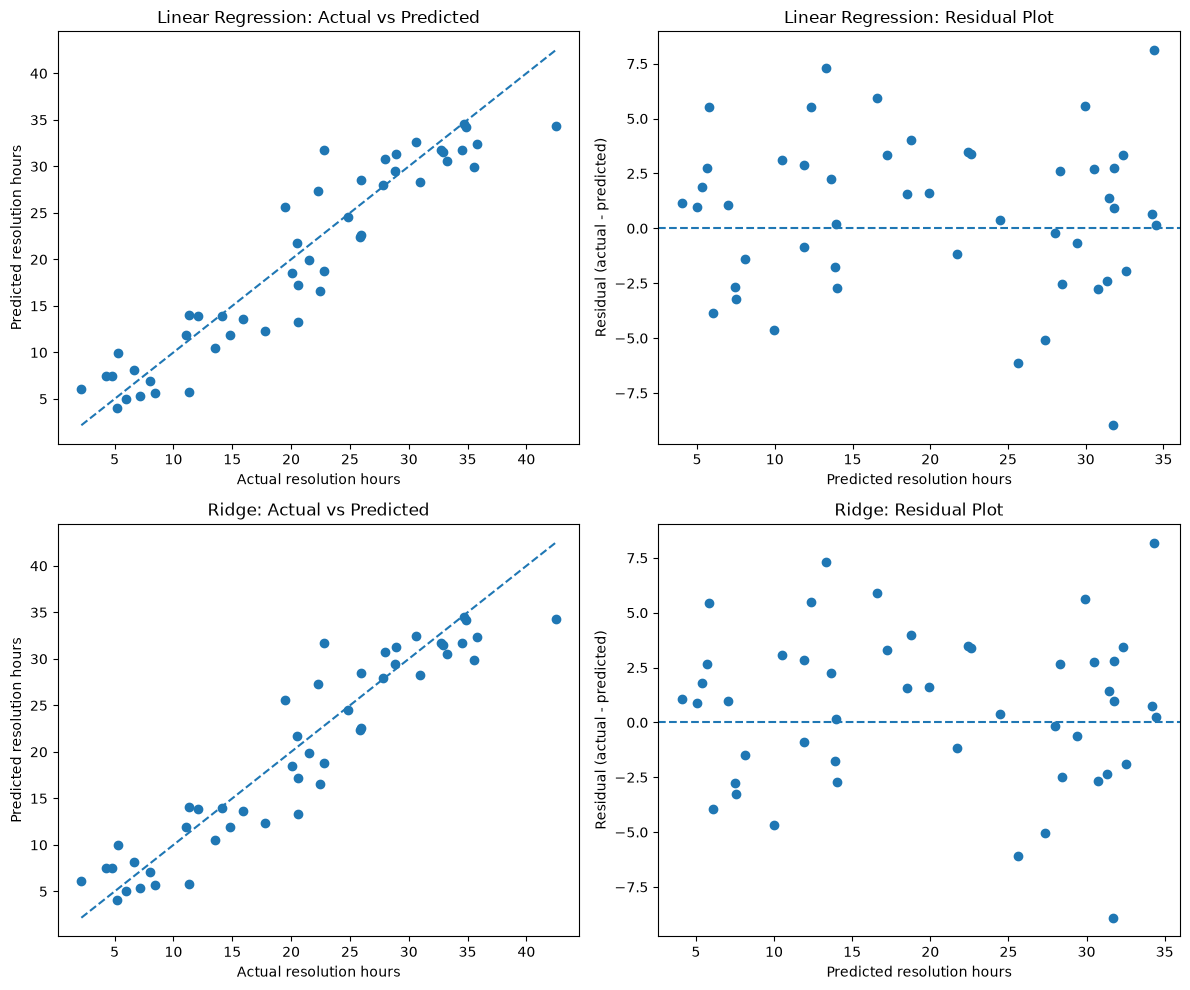

In [12]:
import matplotlib.pyplot as plt

# Compare Linear Regression with the model having the lowest test MAE
best_model_name = results_df.iloc[0]["Model"]

models_to_plot = ["Linear Regression"]

if best_model_name != "Linear Regression":
    models_to_plot.append(best_model_name)

fig, axes = plt.subplots(
    nrows=len(models_to_plot),
    ncols=2,
    figsize=(12, 5 * len(models_to_plot))
)

# Make axes consistent when there is only one model
if len(models_to_plot) == 1:
    axes = np.array([axes])

for i, name in enumerate(models_to_plot):
    pred = predictions[name]

    # Plot 1: actual versus predicted
    axes[i, 0].scatter(y_test, pred)
    axes[i, 0].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )
    axes[i, 0].set_title(f"{name}: Actual vs Predicted")
    axes[i, 0].set_xlabel("Actual resolution hours")
    axes[i, 0].set_ylabel("Predicted resolution hours")

    # Plot 2: residuals
    residuals = y_test - pred
    axes[i, 1].scatter(pred, residuals)
    axes[i, 1].axhline(y=0, linestyle="--")
    axes[i, 1].set_title(f"{name}: Residual Plot")
    axes[i, 1].set_xlabel("Predicted resolution hours")
    axes[i, 1].set_ylabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

8: Visualize the Predictions
I created actual-versus-predicted plots to compare the model's predictions with the real resolution times. I also created residual plots, where a residual is the actual value minus the predicted value. These plots help show prediction errors and whether the model has any noticeable patterns in its mistakes.

10. Why is the mean baseline useful even though it ignores all features?
The mean baseline gives us a simple starting point by predicting the average resolution time for every ticket. It helps us check whether our trained models perform better than simply predicting the average.
11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?
Ridge Regression has the lowest MAE (2.905) and RMSE (3.571). Both metrics identify Ridge as the best-performing model, although its results are almost identical to Linear Regression and Lasso. MAE measures the average absolute prediction error, while RMSE gives more weight to larger errors, so they can sometimes favor different models.
12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?
In my experiment, the polynomial models did not improve performance compared with Linear Regression. This suggests that adding more complex features did not help the model make better predictions on unseen data. Possible overfitting occurs when a model performs well on training data but performs worse on validation data.
13. How did regularization affect performance and coefficient magnitudes?
Ridge and Lasso add a penalty to reduce the size of model coefficients. This can help prevent overfitting. In my experiment, I compared their evaluation scores with Linear Regression to see whether regularization improved prediction performance.
14. Why is scaling included in the Ridge/Lasso pipeline?
Scaling puts the input features on a similar scale. Ridge and Lasso are affected by the size of coefficients, so scaling helps prevent features with larger numerical values from unfairly influencing regularization. The scaler is fitted on training data only to avoid data leakage.
15. Identify one potential leakage issue in the dataset and explain how you handled it.
The lines_changed and reopened columns could cause data leakage because they may only be known after work on a ticket has started or finished. Since the goal is to predict resolution time when a ticket first arrives, I excluded these columns and used only features available at that time.
16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.
A random split may not be appropriate in these cases. If tickets were collected over several years, a time-based split would help test predictions on future tickets. If multiple tickets came from the same customer or team, a group-based split could help prevent related tickets from appearing in both training and testing data.
17. What additional tests would you perform before deploying this model?
Before deploying the model, I would test it on new real-world tickets, check how well it performs for different ticket types and teams, and test how it handles missing or invalid inputs. I would also monitor its prediction errors over time and retrain it if its performance became worse.